# ANFIS para controle climático de estufa

Implementação Takagi–Sugeno de primeira ordem treinada para reproduzir os quatro comandos do controlador especialista. O ANFIS recebe erro de temperatura, erro de umidade e variação da temperatura; cada regra tem consequente linear e pertinências gaussianas. O controlador é direto: prevê os atuadores, não o estado futuro.

A coluna `delta_temperatura_c` original equivale a T(t+1)-T(t), então revelaria o futuro ao controlador. O modelo usa a diferença observada entre T(t) e T(t-1), calculada como `delta_temperatura_anterior_c`.

A partição `particao_sugerida` é preservada. Estatísticas de normalização e parâmetros do modelo são ajustados somente no treino. O teste é reservado para avaliação final.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'data').is_dir())
sys.path.insert(0, str(ROOT / 'scripts'))
from anfis import ANFIS
from simulacao import ControladorFuzzy, ControladorLookahead, estimar_parametros, avaliar

SEED = 42
FIG = ROOT / 'figuras'
FIG.mkdir(exist_ok=True)
base = pd.read_csv(ROOT / 'data' / 'base_aprendizagem_estufa_hibrida.csv')
# O delta_temperatura_c fornecido é T(t+1)-T(t); use a variação passada para evitar vazamento.
base['delta_temperatura_anterior_c'] = base['temperatura_interna_c'].diff().fillna(0)
base.head()

,timestamp,dia_cultivo,passo_no_dia,hora_decimal,fase_cultivo,temperatura_externa_c,umidade_externa_pct,radiacao_solar_w_m2,velocidade_vento_m_s,temperatura_referencia_c,...,sombreamento_pct,consumo_energia_relativo,consumo_agua_relativo,temperatura_interna_t1_c,umidade_interna_t1_pct,indice_estresse_t1,particao_sugerida,delta_temperatura_c,delta_umidade_pct,delta_temperatura_anterior_c
0,2026-01-01 00:00:00,1,0,0.0000,germinacao,24.624,57.929,0.0,2.245,23.5,...,15.530,0.2025,0.2321,23.945,73.421,0.2090,treino,-0.055,-0.579,0.000
1,2026-01-01 00:10:00,1,1,0.1667,germinacao,24.132,62.427,0.0,2.917,23.5,...,14.399,0.2490,0.3010,24.079,73.156,0.2290,treino,0.134,-0.265,-0.055
2,2026-01-01 00:20:00,1,2,0.3333,germinacao,23.903,62.054,0.0,2.848,23.5,...,13.489,0.2548,0.3823,24.241,74.048,0.2229,treino,0.162,0.892,0.134
3,2026-01-01 00:30:00,1,3,0.5000,germinacao,23.768,61.960,0.0,2.749,23.5,...,14.533,0.2484,0.4257,24.173,74.149,0.2136,treino,-0.068,0.101,0.162
4,2026-01-01 00:40:00,1,4,0.6667,germinacao,23.549,61.973,0.0,2.217,23.5,...,13.119,0.2544,0.4431,24.212,75.145,0.1926,treino,0.039,0.996,-0.068


## Exploração inicial

Conferimos integridade, partições, distribuição dos erros e série temporal para contextualizar o conjunto.

(17280, 28)
particao_sugerida
treino       10080
validacao     3600
teste         3600
Name: count, dtype: int64


,erro_temperatura_c,erro_umidade_pct,delta_temperatura_c
count,17280.000000,17280.00000,17280.000000
mean,-0.095018,-6.98732,0.000239
std,3.053095,7.40353,0.197595
min,-9.329000,-28.08900,-0.825000
25%,-2.494500,-11.75650,-0.127000
50%,0.870000,-4.33150,0.012000
75%,2.330000,-1.97475,0.136000
max,6.555000,7.52600,0.731000


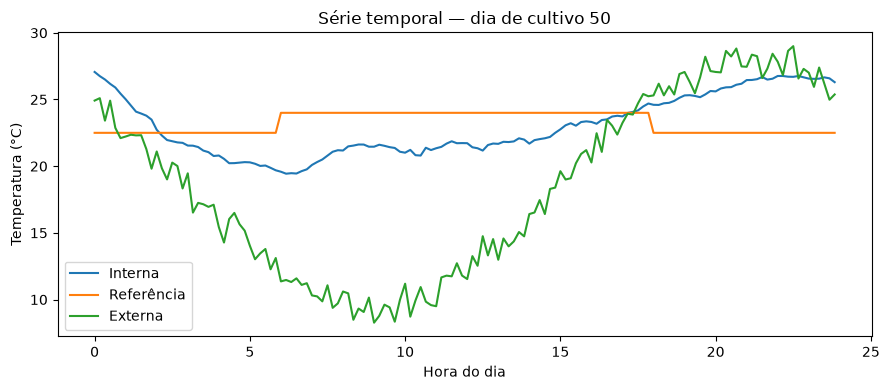

In [2]:
assert base.isna().sum().sum() == 0
print(base.shape)
print(base['particao_sugerida'].value_counts())
display(base[['erro_temperatura_c','erro_umidade_pct','delta_temperatura_c']].describe())
fig, ax = plt.subplots(figsize=(9, 4))
base[base.dia_cultivo == 50].plot(x='hora_decimal', y=['temperatura_interna_c','temperatura_referencia_c','temperatura_externa_c'], ax=ax)
ax.set(xlabel='Hora do dia', ylabel='Temperatura (°C)', title='Série temporal — dia de cultivo 50')
ax.legend(['Interna','Referência','Externa'])
fig.tight_layout(); fig.savefig(FIG/'serie_dia50.png', dpi=160); plt.show()

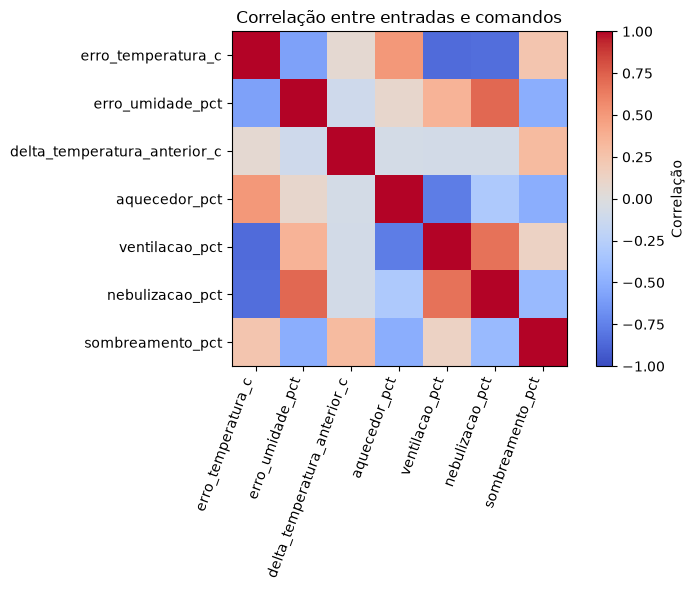

In [3]:
cols = ['erro_temperatura_c','erro_umidade_pct','delta_temperatura_anterior_c','aquecedor_pct','ventilacao_pct','nebulizacao_pct','sombreamento_pct']
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(base[cols].corr(), cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=70, ha='right'); ax.set_yticks(range(len(cols)), cols)
fig.colorbar(image, ax=ax, label='Correlação'); ax.set_title('Correlação entre entradas e comandos')
fig.tight_layout(); fig.savefig(FIG/'correlacao_anfis.png', dpi=160); plt.show()

## Partições e treinamento ANFIS

O modelo tem 3 funções gaussianas por entrada, totalizando 27 regras. Os quatro consequentes de cada regra são funções lineares das entradas. O treinamento minimiza MSE por retropropagação em lotes, com Adam; seleção de estrutura fixa antes de avaliar validação e teste.

In [4]:
FEATURES = ['erro_temperatura_c','erro_umidade_pct','delta_temperatura_anterior_c']
TARGETS = ['aquecedor_pct','ventilacao_pct','nebulizacao_pct','sombreamento_pct']
train = base[base.particao_sugerida == 'treino']
valid = base[base.particao_sugerida == 'validacao']
test = base[base.particao_sugerida == 'teste']

# Escalonamento ajustado exclusivamente no treino.
x_mean, x_std = train[FEATURES].to_numpy().mean(0), train[FEATURES].to_numpy().std(0)
y_mean, y_std = train[TARGETS].to_numpy().mean(0), train[TARGETS].to_numpy().std(0)
x_std[x_std == 0] = 1; y_std[y_std == 0] = 1
def scale_x(frame): return (frame[FEATURES].to_numpy() - x_mean) / x_std
def scale_y(frame): return (frame[TARGETS].to_numpy() - y_mean) / y_std

model = ANFIS(n_mfs=3, learning_rate=0.01, seed=SEED)
model.fit(scale_x(train), scale_y(train), epochs=80, batch_size=512,
          validation_data=(scale_x(valid), scale_y(valid)), patience=10)
def predict(frame): return np.clip(model.predict(scale_x(frame))*y_std + y_mean, 0, 100)
def rmse(frame): return np.sqrt(np.mean((predict(frame)-frame[TARGETS].to_numpy())**2, axis=0))
print('RMSE por atuador (pontos percentuais)')
print(pd.DataFrame({'treino':rmse(train), 'validação':rmse(valid), 'teste':rmse(test)}, index=TARGETS).round(2))
print(f'Regras: {len(model.rules)} | épocas selecionadas: {len(model.loss_history)} | melhor MSE de validação: {min(model.validation_loss_history):.4f}')

RMSE por atuador (pontos percentuais)
                  treino  validação  teste
aquecedor_pct      14.54      15.70  19.83
ventilacao_pct      7.97       8.54   9.48
nebulizacao_pct     6.51      11.15  14.31
sombreamento_pct   17.16      19.17  23.36
Regras: 27 | épocas selecionadas: 21 | melhor MSE de validação: 0.2781


## Figuras do modelo

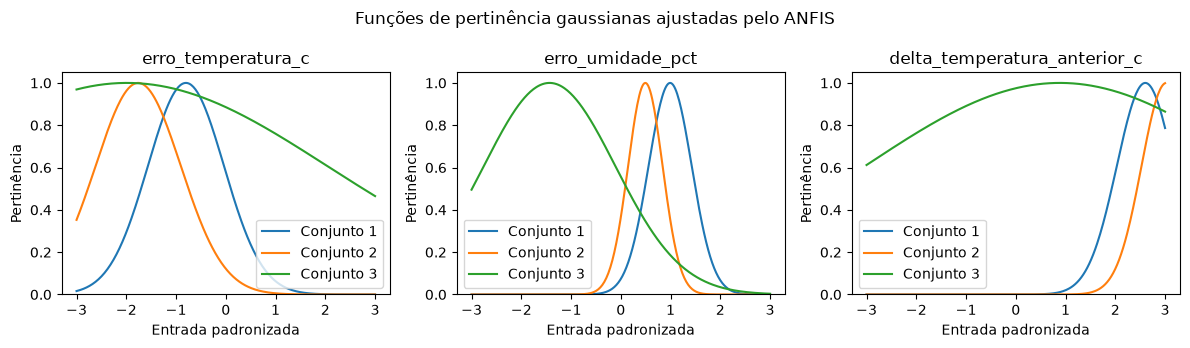

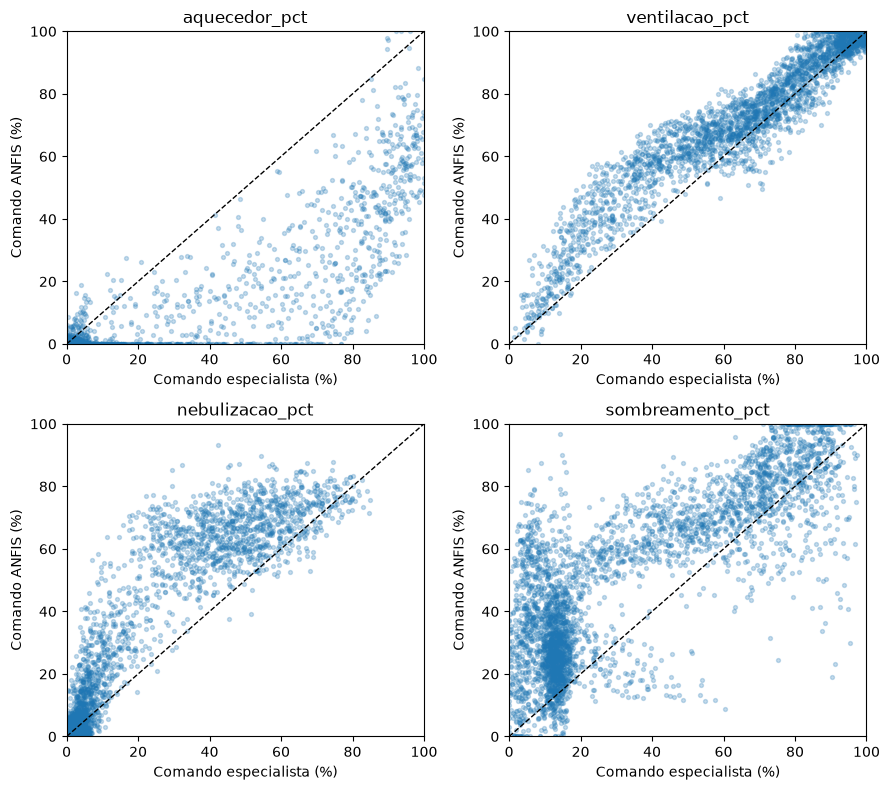

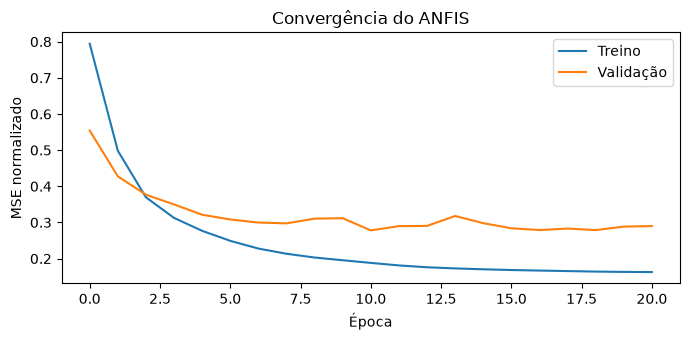

In [5]:
# Funções de pertinência aprendidas nas entradas normalizadas.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for j, ax in enumerate(axes):
    grid = np.linspace(-3, 3, 300)
    for m in range(model.n_mfs):
        mu = np.exp(-.5*((grid-model.centers[j,m])/np.exp(model.log_sigmas[j,m]))**2)
        ax.plot(grid, mu, label=f'Conjunto {m+1}')
    ax.set(title=FEATURES[j], xlabel='Entrada padronizada', ylabel='Pertinência', ylim=(0,1.05)); ax.legend()
fig.suptitle('Funções de pertinência gaussianas ajustadas pelo ANFIS')
fig.tight_layout(); fig.savefig(FIG/'funcoes_pertinencia_anfis.png', dpi=160); plt.show()

# Previsão contra comando especialista na partição de teste.
yhat, ytrue = predict(test), test[TARGETS].to_numpy()
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for j, ax in enumerate(axes.flat):
    ax.scatter(ytrue[:,j], yhat[:,j], s=8, alpha=.25)
    ax.plot([0,100],[0,100],'k--',lw=1); ax.set(xlim=(0,100),ylim=(0,100),xlabel='Comando especialista (%)',ylabel='Comando ANFIS (%)',title=TARGETS[j])
fig.tight_layout(); fig.savefig(FIG/'anfis_real_predito_teste.png', dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(7,3.5)); ax.plot(model.loss_history, label='Treino'); ax.plot(model.validation_loss_history, label='Validação')
ax.set(xlabel='Época',ylabel='MSE normalizado',title='Convergência do ANFIS'); ax.legend(); fig.tight_layout()
fig.savefig(FIG/'treinamento_anfis.png', dpi=160); plt.show()

## Uso do controlador treinado

Em uma aplicação, as mesmas três entradas devem ser calculadas a cada passo. O resultado tem quatro comandos percentuais limitados a [0, 100]. A avaliação neste notebook mede imitação do controlador especialista; resultados não equivalem a desempenho em malha fechada. Para comparar controladores nos episódios, é necessário acoplar estes comandos ao simulador dinâmico e calcular as métricas por episódio indicadas no tutorial.

In [6]:
def controlador_anfis(erro_temperatura, erro_umidade, delta_temperatura):
    entrada = (np.array([[erro_temperatura, erro_umidade, delta_temperatura]]) - x_mean) / x_std
    saida = model.predict(entrada)[0] * y_std + y_mean
    return dict(zip(TARGETS, np.clip(saida, 0, 100)))

controlador_anfis(-1.0, 8.0, 0.1)

{'aquecedor_pct': np.float64(8.702544226801885),
 'ventilacao_pct': np.float64(79.98707614902182),
 'nebulizacao_pct': np.float64(51.84699250336837),
 'sombreamento_pct': np.float64(27.992965174118748)}

## Simulação em malha fechada

O baseline fuzzy Sugeno usa 15 regras singleton para erro térmico, erro de umidade e variação térmica passada, além de 3 regras solares para sombreamento. Os parâmetros físicos do simulador são calibrados com as partições treino e validação da série histórica, excluindo a partição teste e os episódios fechados. Cada controlador começa do mesmo estado inicial e recebe a mesma sequência de ruído por episódio. O ANFIS e seus escalonadores continuam ajustados somente no treino.

As pertinências são triangulares, com ombros nas extremidades dos universos apresentados na figura. Cada bloco de regras é defuzzificado por média ponderada de singletons. A combinação das saídas usa máximo para ventilação e sombreamento, a saída de umidade para nebulização e a regra `clip(aquecimento_térmico + 0,15·aquecimento_dinâmico − 0,20·nebulização, 0, 1)` para o aquecedor. As três regras solares atuam no sombreamento.


Antes do teste final, os ganhos de correção de ventilação/nebulização são escolhidos em oito episódios da validação (dias 88–95), após calibrar o simulador em treino e dias de validação até 87. Como a primeira busca selecionou o limite superior de nebulização, a busca ampliada usa ganhos de ventilação {0; 0,3; 0,6; 0,9} e nebulização {0,4; 0,7; 1,0}. Minimiza-se RMSE_T/1 °C + RMSE_H/5 p.p. + 5·taxa de violação. Os 20 episódios de teste não participam da escolha.


No lookahead de um passo, a primeira ação é aplicada ao simulador sem ruído para prever T e H no passo seguinte. O controlador recalcula a ação usando o estado previsto; as duas ações são combinadas pelo peso escolhido na validação. Durante essa previsão, setpoints e variáveis externas atuais são mantidos constantes. O teste final compara cada controlador com e sem lookahead nos mesmos 20 episódios.


Frio/seco — [aquecedor, ventilação, nebulização, sombra]: [1.   0.04 0.   0.94]
Quente/úmido — [aquecedor, ventilação, nebulização, sombra]: [0.   0.95 0.   1.  ]


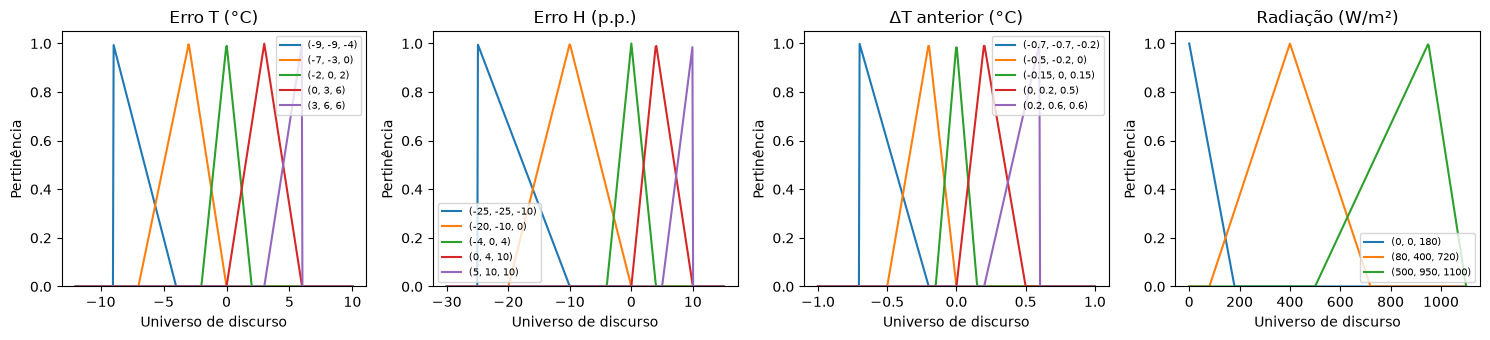

In [7]:
# Verificação do baseline em dois cenários extremos antes da avaliação.
fuzzy = ControladorFuzzy()
acoes_frio_seco = fuzzy(6.0, 20.0, -0.3, 700)
acoes_quente_umido = fuzzy(-8.0, -20.0, 0.5, 900)
assert np.isfinite(acoes_frio_seco).all() and np.isfinite(acoes_quente_umido).all()
assert ((acoes_frio_seco >= 0) & (acoes_frio_seco <= 1)).all()
assert ((acoes_quente_umido >= 0) & (acoes_quente_umido <= 1)).all()
print('Frio/seco — [aquecedor, ventilação, nebulização, sombra]:', acoes_frio_seco.round(2))
print('Quente/úmido — [aquecedor, ventilação, nebulização, sombra]:', acoes_quente_umido.round(2))

# Desenho das pertinências triangulares usadas no baseline.
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, var, title, grid in zip(axes, ['eT','eH','dT','rad'], ['Erro T (°C)','Erro H (p.p.)','ΔT anterior (°C)','Radiação (W/m²)'], [np.linspace(-12,10,400), np.linspace(-30,15,400), np.linspace(-1,1,400), np.linspace(0,1100,400)]):
    for _, (rv, pars, _) in enumerate(fuzzy._regras):
        if rv == var:
            vals = [__import__('simulacao').pertinencia_triangular(x, *pars) for x in grid]
            ax.plot(grid, vals, label=f'{pars}')
    ax.set(title=title, xlabel='Universo de discurso', ylabel='Pertinência', ylim=(0,1.05)); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG/'funcoes_pertinencia_baseline.png', dpi=160); plt.show()

In [8]:
# Calibração do simulador exclui dias de validação que serão usados para selecionar ganhos.
calibracao = base[(base.particao_sugerida == 'treino') |
                  ((base.particao_sugerida == 'validacao') & (base.dia_cultivo <= 87))]
parametros = estimar_parametros(calibracao)
print('Parâmetros calibrados sem usar validação de ajuste nem teste:', parametros)

# Dias 88–95 da validação formam oito episódios fechados para escolha dos ganhos.
val_rows = base[(base.particao_sugerida == 'validacao') &
                (base.fase_cultivo == 'floracao') & base.dia_cultivo.between(88, 95)]
val_episodios, val_meta = [], []
for episodio_id, (_, dia) in enumerate(val_rows.groupby('dia_cultivo', sort=True), start=1):
    primeiro = dia.iloc[0]
    trecho = dia[['fase_cultivo','temperatura_externa_c','umidade_externa_pct',
                  'radiacao_solar_w_m2','velocidade_vento_m_s',
                  'temperatura_referencia_c','umidade_referencia_pct']].copy()
    trecho.insert(0, 'passo_episodio', np.arange(len(trecho)))
    trecho.insert(0, 'episodio_id', episodio_id)
    val_episodios.append(trecho)
    val_meta.append({'episodio_id': episodio_id,
                     'temperatura_inicial_c': primeiro.temperatura_interna_c,
                     'umidade_inicial_pct': primeiro.umidade_interna_pct})
val_episodios = pd.concat(val_episodios, ignore_index=True)
val_meta = pd.DataFrame(val_meta)
assert val_episodios.episodio_id.nunique() == 8

# Os dois controladores recebem a mesma correção e a mesma semente em cada episódio.
def corrigir_umidade(controlador, ganho_vent, ganho_neb):
    def controle(erro_t, erro_h, delta_t, radiacao=0.0):
        acoes = np.asarray(controlador(erro_t, erro_h, delta_t, radiacao), float).copy()
        acoes[1] += ganho_vent * np.clip(-erro_h/15, 0, 1)
        acoes[2] += ganho_neb * np.clip(erro_h/15, -1, 1)
        return np.clip(acoes, 0, 1)
    return controle

def controlador_anfis_normalizado(erro_t, erro_h, delta_t, radiacao=0.0):
    x = (np.array([[erro_t, erro_h, delta_t]]) - x_mean) / x_std
    comando_pct = model.predict(x)[0] * y_std + y_mean
    return np.clip(comando_pct / 100, 0, 1)

fuzzy_base = ControladorFuzzy()
grade = [(kv, kn) for kv in (0.0, .3, .6, .9) for kn in (.4, .7, 1.0)]
linhas_grade = []
for ganho_vent, ganho_neb in grade:
    avaliacao, _ = avaliar(
        val_episodios, val_meta,
        corrigir_umidade(controlador_anfis_normalizado, ganho_vent, ganho_neb),
        parametros, base_seed=3000,
        fuzzy_controller=corrigir_umidade(fuzzy_base, ganho_vent, ganho_neb))
    for nome, grupo in avaliacao.groupby('controlador'):
        medias = grupo[['RMSE_T','RMSE_H','violacao']].mean()
        # Score pré-definido: erro por tolerância + penalidade cinco vezes maior para violações.
        score = medias.RMSE_T/1.0 + medias.RMSE_H/5.0 + 5*medias.violacao
        linhas_grade.append({'controlador':nome,'ganho_vent':ganho_vent,
                             'ganho_neb':ganho_neb,'score_validacao':score,
                             **{f'{k}_validacao':v for k,v in medias.items()}})

ajustes = pd.DataFrame(linhas_grade)
melhores = ajustes.loc[ajustes.groupby('controlador').score_validacao.idxmin()].set_index('controlador')
OUT = ROOT/'resultados'; OUT.mkdir(exist_ok=True)
ajustes.to_csv(OUT/'grade_ajuste_validacao.csv', index=False)
melhores.to_csv(OUT/'ganhos_selecionados.csv')
print('Ganhos selecionados exclusivamente na validação:')
display(melhores.round(4))

fuzzy_tunado = corrigir_umidade(fuzzy_base, melhores.loc['fuzzy','ganho_vent'],
                                melhores.loc['fuzzy','ganho_neb'])
anfis_tunado = corrigir_umidade(controlador_anfis_normalizado,
                                melhores.loc['anfis','ganho_vent'],
                                melhores.loc['anfis','ganho_neb'])

# Seleciona peso do lookahead nos mesmos episódios de validação; inclui quatro valores do tutorial.
grade_lookahead = (.1, .2, .35, .5)
linhas_lookahead = []
for peso in grade_lookahead:
    fuzzy_la = ControladorLookahead(fuzzy_tunado, parametros, peso)
    anfis_la = ControladorLookahead(anfis_tunado, parametros, peso)
    avaliacao, _ = avaliar(val_episodios, val_meta, anfis_la, parametros,
                           base_seed=3000, fuzzy_controller=fuzzy_la)
    for nome, grupo in avaliacao.groupby('controlador'):
        medias = grupo[['RMSE_T','RMSE_H','violacao']].mean()
        score = medias.RMSE_T/1.0 + medias.RMSE_H/5.0 + 5*medias.violacao
        linhas_lookahead.append({'controlador':nome, 'peso':peso,
                                 'score_validacao':score,
                                 **{f'{k}_validacao':v for k,v in medias.items()}})

pesos = pd.DataFrame(linhas_lookahead)
melhores_pesos = pesos.loc[pesos.groupby('controlador').score_validacao.idxmin()].set_index('controlador')
pesos.to_csv(OUT/'grade_lookahead_validacao.csv', index=False)
melhores_pesos.to_csv(OUT/'pesos_lookahead_selecionados.csv')
print('Pesos lookahead escolhidos na validação:')
display(melhores_pesos.round(4))

# Teste final: quatro variantes, todas com as mesmas condições e ruídos pareados.
episodios = pd.read_csv(ROOT/'data'/'episodios_teste_controle.csv')
metadados = pd.read_csv(ROOT/'data'/'metadados_episodios_teste.csv')
base_resultados, base_trajetorias = avaliar(episodios, metadados, anfis_tunado,
                                            parametros, base_seed=1000,
                                            fuzzy_controller=fuzzy_tunado)
fuzzy_la = ControladorLookahead(fuzzy_tunado, parametros, melhores_pesos.loc['fuzzy','peso'])
anfis_la = ControladorLookahead(anfis_tunado, parametros, melhores_pesos.loc['anfis','peso'])
la_resultados, la_trajetorias = avaliar(episodios, metadados, anfis_la,
                                        parametros, base_seed=1000,
                                        fuzzy_controller=fuzzy_la)
la_resultados['controlador'] = la_resultados['controlador'] + '_lookahead'
resultados = pd.concat([base_resultados, la_resultados], ignore_index=True)
trajetorias = {**base_trajetorias,
               'fuzzy_lookahead':la_trajetorias['fuzzy'],
               'anfis_lookahead':la_trajetorias['anfis']}
assert resultados.episodio_id.nunique() == 20 and resultados.groupby('controlador').size().eq(20).all()
resultados.head()

Parâmetros calibrados sem usar validação de ajuste nem teste: {'tau': {'floracao': 0.8452005696428395, 'germinacao': 0.6826759096428857, 'vegetativo': 1.0528380165714322}, 'sigma_t': 0.09956257122342047, 'sigma_h': {'floracao': 0.43710320695651556, 'germinacao': 0.44444596545112197, 'vegetativo': 0.44942488979941475}}


Ganhos selecionados exclusivamente na validação:


,ganho_vent,ganho_neb,score_validacao,RMSE_T_validacao,RMSE_H_validacao,violacao_validacao
controlador,,,,,,
anfis,0.0,1.0,9.4871,2.6325,12.1157,0.8863
fuzzy,0.0,1.0,12.8234,5.6053,13.2823,0.9123


Pesos lookahead escolhidos na validação:


,peso,score_validacao,RMSE_T_validacao,RMSE_H_validacao,violacao_validacao
controlador,,,,,
anfis,0.35,9.4864,2.6382,12.1489,0.8837
fuzzy,0.10,12.8187,5.6045,13.2632,0.9123


,episodio_id,controlador,RMSE_T,RMSE_H,IAE,violacao,consumo_E,consumo_A
0,1,fuzzy,5.228964,12.979141,759.780520,0.944444,0.153851,0.088722
1,1,anfis,2.596637,11.768728,456.867319,0.916667,0.198746,0.148326
2,2,fuzzy,5.215709,11.679693,768.635198,0.944444,0.142175,0.101512
3,2,anfis,2.802592,10.783417,468.381289,0.923611,0.173365,0.168346
4,3,fuzzy,5.126664,12.454182,768.294946,0.923611,0.150973,0.087642


## Métricas, teste pareado e exportação

As tolerâncias de violação são 1 °C e 5 pontos percentuais; o IAE usa λ=0,1. Consumos são as médias dos comandos relativos de aquecedor e nebulizador. O Wilcoxon pareado compara lookahead com o controlador sem lookahead e ANFIS com fuzzy lookahead (α=0,05); testes bilaterais e Shapiro são exportados como informação complementar.


In [9]:
METRICAS = ['RMSE_T','RMSE_H','IAE','violacao','consumo_E','consumo_A']
tabela = pd.concat([resultados.pivot(index='episodio_id', columns='controlador', values=m).rename(columns=lambda c: f'{m}_{c}') for m in METRICAS], axis=1)
OUT = ROOT/'resultados'; OUT.mkdir(exist_ok=True)
resultados.to_csv(OUT/'metricas_por_episodio.csv', index=False)
tabela.to_csv(OUT/'comparacao_pareada.csv')
resumo = resultados.groupby('controlador')[METRICAS].agg(['mean','std']).round(4)
resumo.to_csv(OUT/'resumo_controladores.csv')

from scipy.stats import wilcoxon, shapiro
comparacoes = [('lookahead_anfis_vs_anfis','anfis_lookahead','anfis'),
               ('lookahead_fuzzy_vs_fuzzy','fuzzy_lookahead','fuzzy'),
               ('anfis_lookahead_vs_fuzzy_lookahead','anfis_lookahead','fuzzy_lookahead')]
linhas = []
for nome, candidato, referencia in comparacoes:
    for metrica in ['RMSE_T','RMSE_H','IAE','violacao']:
        diferenca = tabela[f'{metrica}_{candidato}'] - tabela[f'{metrica}_{referencia}']
        w2 = wilcoxon(diferenca, alternative='two-sided', zero_method='wilcox')
        w1 = wilcoxon(diferenca, alternative='less', zero_method='wilcox')
        linhas.append({'comparacao':nome,'metrica':metrica,'W':w2.statistic,
                       'p_bilateral':w2.pvalue,'p_unilateral_menor':w1.pvalue,
                       'p_shapiro':shapiro(diferenca).pvalue,
                       'diferenca_media_candidato_menos_referencia':diferenca.mean(),
                       'diferenca_mediana_candidato_menos_referencia':diferenca.median(),
                       'rejeita_H0_alpha_005':w1.pvalue < .05})
estatistica = pd.DataFrame(linhas)
estatistica.to_csv(OUT/'teste_lookahead.csv', index=False)
print('H1 unilateral: a métrica do candidato é menor que a referência; α=0,05')
display(resumo); display(estatistica.round(5))

H1 unilateral: a métrica do candidato é menor que a referência; α=0,05


RMSE_T           RMSE_H               IAE          violacao  \
                   mean     std     mean     std      mean      std     mean   
controlador                                                                    
anfis            3.3284  0.4423  13.1586  1.0011  569.6119  60.9355   0.9604   
anfis_lookahead  3.3288  0.4440  13.1611  0.9976  569.7942  61.1969   0.9580   
fuzzy            4.4166  0.5708  11.5937  1.3938  671.7735  67.9063   0.9545   
fuzzy_lookahead  4.4100  0.5668  11.5774  1.3685  670.8189  67.3457   0.9545   

                        consumo_E         consumo_A          
                    std      mean     std      mean     std  
controlador                                                  
anfis            0.0267    0.1221  0.0441    0.1535  0.0165  
anfis_lookahead  0.0276    0.1223  0.0443    0.1531  0.0166  
fuzzy            0.0188    0.2420  0.0704    0.0868  0.0124  
fuzzy_lookahead  0.0190    0.2430  0.0695    0.0867  0.0124

,comparacao,metrica,W,p_bilateral,p_unilateral_menor,p_shapiro,diferenca_media_candidato_menos_referencia,diferenca_mediana_candidato_menos_referencia,rejeita_H0_alpha_005
0,lookahead_anfis_vs_anfis,RMSE_T,99.0,0.84082,0.59382,0.67101,0.00040,-0.00001,False
1,lookahead_anfis_vs_anfis,RMSE_H,83.0,0.43043,0.79545,0.78564,0.00245,0.00320,False
2,lookahead_anfis_vs_anfis,IAE,88.0,0.54588,0.73916,0.33705,0.18229,0.15422,False
3,lookahead_anfis_vs_anfis,violacao,0.0,0.03936,0.01968,0.00000,-0.00243,0.00000,True
4,lookahead_fuzzy_vs_fuzzy,RMSE_T,24.0,0.00143,0.00072,0.00000,-0.00653,-0.00090,True
5,lookahead_fuzzy_vs_fuzzy,RMSE_H,81.0,0.38838,0.19419,0.00000,-0.01629,-0.00060,False
6,lookahead_fuzzy_vs_fuzzy,IAE,22.0,0.00102,0.00051,0.00000,-0.95460,-0.21058,True
7,lookahead_fuzzy_vs_fuzzy,violacao,1.0,0.65472,0.67264,0.00000,0.00000,0.00000,False
8,anfis_lookahead_vs_fuzzy_lookahead,RMSE_T,0.0,0.00000,0.00000,0.00086,-1.08125,-0.45170,True
9,anfis_lookahead_vs_fuzzy_lookahead,RMSE_H,34.0,0.00639,0.99721,0.00080,1.58368,2.83676,False


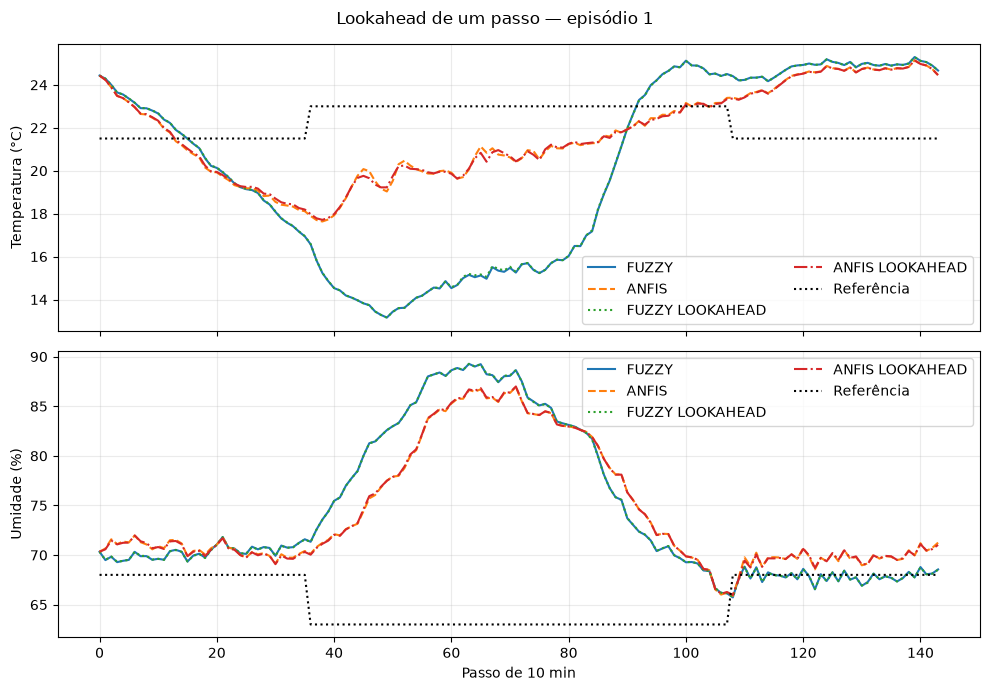

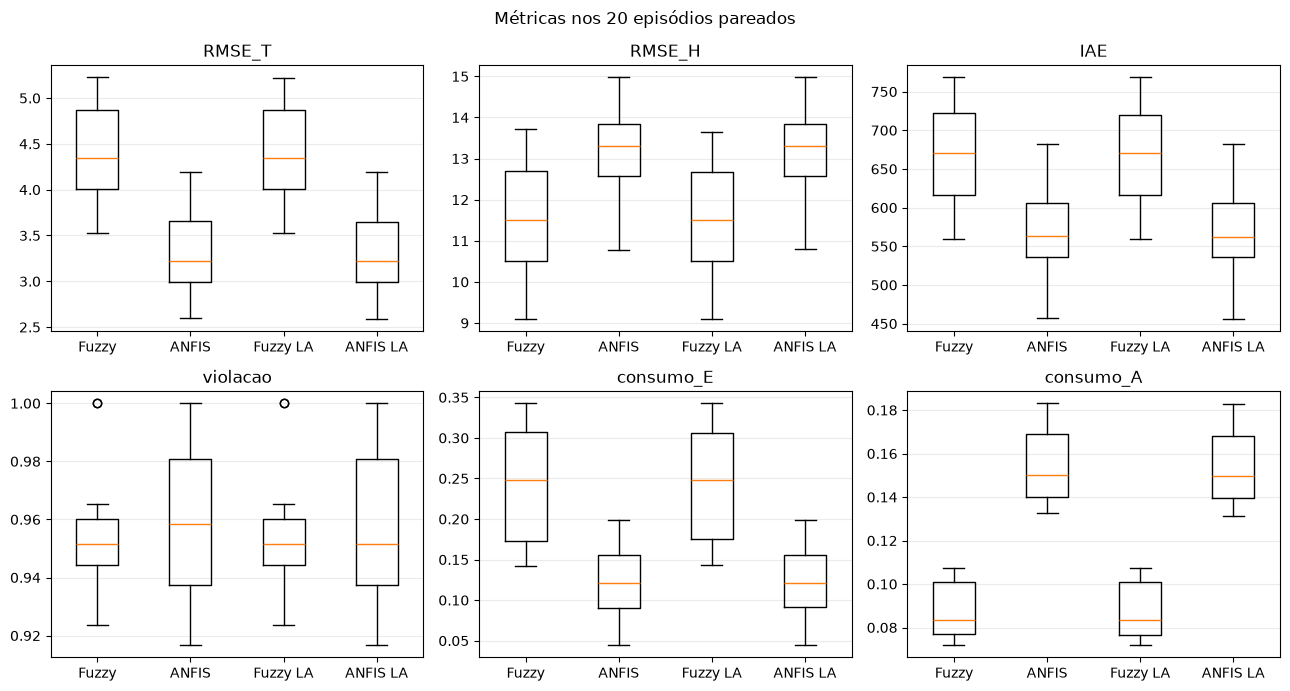

In [10]:
# Episódio 1: base ajustada e lookahead para os dois controladores.
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
estilos = {'fuzzy':'-', 'anfis':'--', 'fuzzy_lookahead':':', 'anfis_lookahead':'-.'}
for ax, var, ref, ylabel in [(axes[0],'temperatura','referencia_t','Temperatura (°C)'), (axes[1],'umidade','referencia_h','Umidade (%)')]:
    for nome, estilo in estilos.items():
        d = trajetorias[nome][1]
        ax.plot(d['passo'], d[var], estilo, label=nome.replace('_',' ').upper())
    ax.plot(d['passo'], d[ref], 'k:', label='Referência')
    ax.set_ylabel(ylabel); ax.grid(alpha=.25); ax.legend(ncol=2)
axes[-1].set_xlabel('Passo de 10 min'); fig.suptitle('Lookahead de um passo — episódio 1')
fig.tight_layout(); fig.savefig(FIG/'lookahead_episodio01.png', dpi=160); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
nome_modelos = ['fuzzy','anfis','fuzzy_lookahead','anfis_lookahead']
for ax, m in zip(axes.flat, METRICAS):
    ax.boxplot([tabela[f'{m}_{nome}'] for nome in nome_modelos])
    ax.set_xticks(range(1,5), ['Fuzzy','ANFIS','Fuzzy LA','ANFIS LA'])
    ax.set_title(m); ax.grid(axis='y', alpha=.25)
fig.suptitle('Métricas nos 20 episódios pareados')
fig.tight_layout(); fig.savefig(FIG/'lookahead_metricas_20_episodios.png', dpi=160); plt.show()

## Preditor de transição e otimização MPC

Treinamos MLPs para prever T(t+1) e H(t+1) a partir do estado, ambiente, setpoints, fase de cultivo e quatro atuadores. Os escalonadores são ajustados apenas no treino; a arquitetura é escolhida em dias de validação anteriores aos usados para ajustar os controladores.

Em cada passo, o MPC compara a ação-base com pequenas mudanças individuais e combinações para aquecimento/sombreamento e ventilação/nebulização. O custo penaliza erro previsto normalizado, esforço em relação à ação-base e, levemente, aquecimento e nebulização. A busca é local e mantém as ações próximas à região coberta pelos dados.

In [11]:
from preditor import PreditorTransicao, ControladorMPC

validacao_preditor = base[(base.particao_sugerida == 'validacao') & (base.dia_cultivo <= 87)]
preditor = PreditorTransicao(seed=42).fit(base, validacao=validacao_preditor)
print('Arquitetura escolhida:', preditor.arquitetura, '| épocas:', preditor.modelo.n_iter_)
display(pd.DataFrame(preditor.resultados_arquiteturas).round(4))
metricas_preditor = pd.DataFrame(preditor.metricas).T
metricas_preditor.to_csv(OUT/'metricas_preditor_transicao.csv')
pd.DataFrame(preditor.resultados_arquiteturas).to_csv(OUT/'arquiteturas_preditor.csv', index=False)
display(metricas_preditor.round(4))

Arquitetura escolhida: (128, 64, 32) | épocas: 35


,arquitetura,RMSE_T_validacao,RMSE_H_validacao,score_validacao,epocas
0,"(64, 32)",0.6871,0.6710,0.8213,59
1,"(128, 64, 32)",0.4776,0.9222,0.6620,35


,RMSE_T,RMSE_H
treino,0.1132,0.4454
validacao,0.4776,0.9222
teste,0.7194,1.3252


### Seleção do custo de esforço na validação

A seleção usa os mesmos oito episódios de validação (dias 88–95), com ruído pareado entre controladores. O preditor e sua arquitetura já foram selecionados sem esses dias. Os 20 episódios finais seguem reservados.

In [12]:
pesos_esforco = (0.0, 1.0, 5.0, 20.0)
linhas_mpc_validacao = []
for peso in pesos_esforco:
    fuzzy_mpc = ControladorMPC(fuzzy_tunado, preditor, peso_esforco=peso)
    anfis_mpc = ControladorMPC(anfis_tunado, preditor, peso_esforco=peso)
    avaliacao, _ = avaliar(val_episodios, val_meta, anfis_mpc, parametros,
                           base_seed=3000, fuzzy_controller=fuzzy_mpc)
    for nome, grupo in avaliacao.groupby('controlador'):
        medias = grupo[['RMSE_T','RMSE_H','violacao']].mean()
        score = medias.RMSE_T/1.0 + medias.RMSE_H/5.0 + 5*medias.violacao
        linhas_mpc_validacao.append({'controlador':nome,'peso_esforco':peso,
                                     'score_validacao':score,
                                     **{f'{k}_validacao':v for k,v in medias.items()}})
tabela_mpc_validacao = pd.DataFrame(linhas_mpc_validacao)
melhor_peso_mpc = tabela_mpc_validacao.loc[tabela_mpc_validacao.groupby('controlador').score_validacao.idxmin()].set_index('controlador')
tabela_mpc_validacao.to_csv(OUT/'grade_mpc_validacao.csv', index=False)
melhor_peso_mpc.to_csv(OUT/'peso_mpc_selecionado.csv')
display(melhor_peso_mpc.round(4))

,peso_esforco,score_validacao,RMSE_T_validacao,RMSE_H_validacao,violacao_validacao
controlador,,,,,
anfis,1.0,9.3694,2.6279,11.7888,0.8767
fuzzy,0.0,12.0896,4.6724,14.3867,0.9080


In [13]:
# Avaliação final dos controladores-base e suas variantes MPC nos mesmos episódios/sementes.
fuzzy_mpc = ControladorMPC(fuzzy_tunado, preditor, melhor_peso_mpc.loc['fuzzy','peso_esforco'])
anfis_mpc = ControladorMPC(anfis_tunado, preditor, melhor_peso_mpc.loc['anfis','peso_esforco'])
metricas_mpc, trajetorias_mpc = avaliar(episodios, metadados, anfis_mpc, parametros,
                                        base_seed=1000, fuzzy_controller=fuzzy_mpc)
metricas_mpc['controlador'] += '_mpc'
resultados_mpc = pd.concat([base_resultados, metricas_mpc], ignore_index=True)
traj_mpc = {**base_trajetorias, 'fuzzy_mpc':trajetorias_mpc['fuzzy'],
            'anfis_mpc':trajetorias_mpc['anfis']}
tabela_mpc = pd.concat([resultados_mpc.pivot(index='episodio_id', columns='controlador', values=m).rename(columns=lambda c:f'{m}_{c}') for m in METRICAS], axis=1)
resultados_mpc.to_csv(OUT/'metricas_mpc_por_episodio.csv', index=False)
tabela_mpc.to_csv(OUT/'comparacao_mpc_pareada.csv')
resumo_mpc = resultados_mpc.groupby('controlador')[METRICAS].agg(['mean','std']).round(4)
resumo_mpc.to_csv(OUT/'resumo_mpc.csv')
display(resumo_mpc)

RMSE_T           RMSE_H               IAE          violacao  \
               mean     std     mean     std      mean      std     mean   
controlador                                                                
anfis        3.3284  0.4423  13.1586  1.0011  569.6119  60.9355   0.9604   
anfis_mpc    3.3033  0.4464  12.7128  1.1516  550.5573  64.4870   0.9535   
fuzzy        4.4166  0.5708  11.5937  1.3938  671.7735  67.9063   0.9545   
fuzzy_mpc    4.0852  0.2747  12.8459  1.8986  621.1799  34.3425   0.9531   

                    consumo_E         consumo_A          
                std      mean     std      mean     std  
controlador                                              
anfis        0.0267    0.1221  0.0441    0.1535  0.0165  
anfis_mpc    0.0335    0.1553  0.0413    0.1544  0.0159  
fuzzy        0.0188    0.2420  0.0704    0.0868  0.0124  
fuzzy_mpc    0.0200    0.2220  0.0388    0.0928  0.0080

In [14]:
# Wilcoxon unilateral para redução por MPC e comparação ANFIS-MPC vs fuzzy-MPC.
comparacoes_mpc = [('fuzzy_mpc_vs_fuzzy','fuzzy_mpc','fuzzy'),
                   ('anfis_mpc_vs_anfis','anfis_mpc','anfis'),
                   ('anfis_mpc_vs_fuzzy_mpc','anfis_mpc','fuzzy_mpc')]
linhas = []
for nome, candidato, referencia in comparacoes_mpc:
    for metrica in ['RMSE_T','RMSE_H','IAE','violacao']:
        diferenca = tabela_mpc[f'{metrica}_{candidato}'] - tabela_mpc[f'{metrica}_{referencia}']
        bil = wilcoxon(diferenca, alternative='two-sided', zero_method='wilcox')
        uni = wilcoxon(diferenca, alternative='less', zero_method='wilcox')
        linhas.append({'comparacao':nome,'metrica':metrica,'W':bil.statistic,
                       'p_bilateral':bil.pvalue,'p_unilateral_menor':uni.pvalue,
                       'diferenca_media':diferenca.mean(),'diferenca_mediana':diferenca.median(),
                       'rejeita_H0_alpha_005':uni.pvalue < .05})
teste_mpc = pd.DataFrame(linhas)
teste_mpc.to_csv(OUT/'wilcoxon_mpc.csv', index=False)
display(teste_mpc.round(5))

,comparacao,metrica,W,p_bilateral,p_unilateral_menor,diferenca_media,diferenca_mediana,rejeita_H0_alpha_005
0,fuzzy_mpc_vs_fuzzy,RMSE_T,25.0,0.00169,0.00084,-0.33136,-0.29147,True
1,fuzzy_mpc_vs_fuzzy,RMSE_H,0.0,0.00000,1.00000,1.25222,0.60615,False
2,fuzzy_mpc_vs_fuzzy,IAE,21.0,0.00085,0.00043,-50.59358,-51.15240,True
3,fuzzy_mpc_vs_fuzzy,violacao,28.0,0.38076,0.19038,-0.00139,0.00000,False
4,anfis_mpc_vs_anfis,RMSE_T,24.0,0.00143,0.00072,-0.02509,-0.02780,True
5,anfis_mpc_vs_anfis,RMSE_H,1.0,0.00000,0.00000,-0.44585,-0.50727,True
6,anfis_mpc_vs_anfis,IAE,0.0,0.00000,0.00000,-19.05465,-20.04286,True
7,anfis_mpc_vs_anfis,violacao,16.0,0.00674,0.00337,-0.00694,-0.00694,True
8,anfis_mpc_vs_fuzzy_mpc,RMSE_T,0.0,0.00000,0.00000,-0.78191,-0.84125,True
9,anfis_mpc_vs_fuzzy_mpc,RMSE_H,102.0,0.92728,0.46364,-0.13313,-1.07517,False


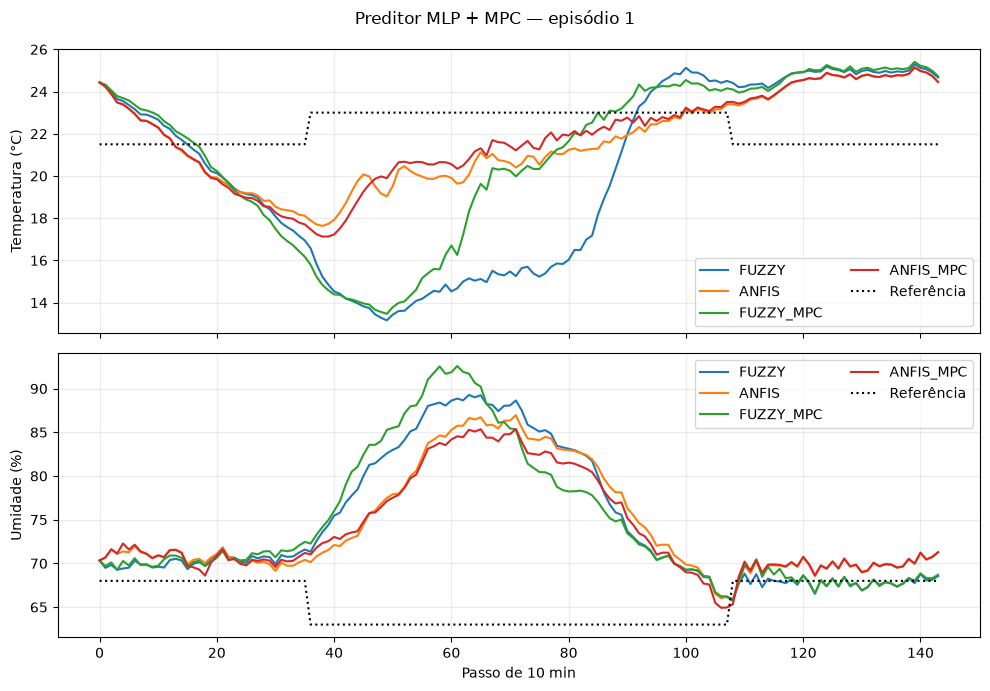

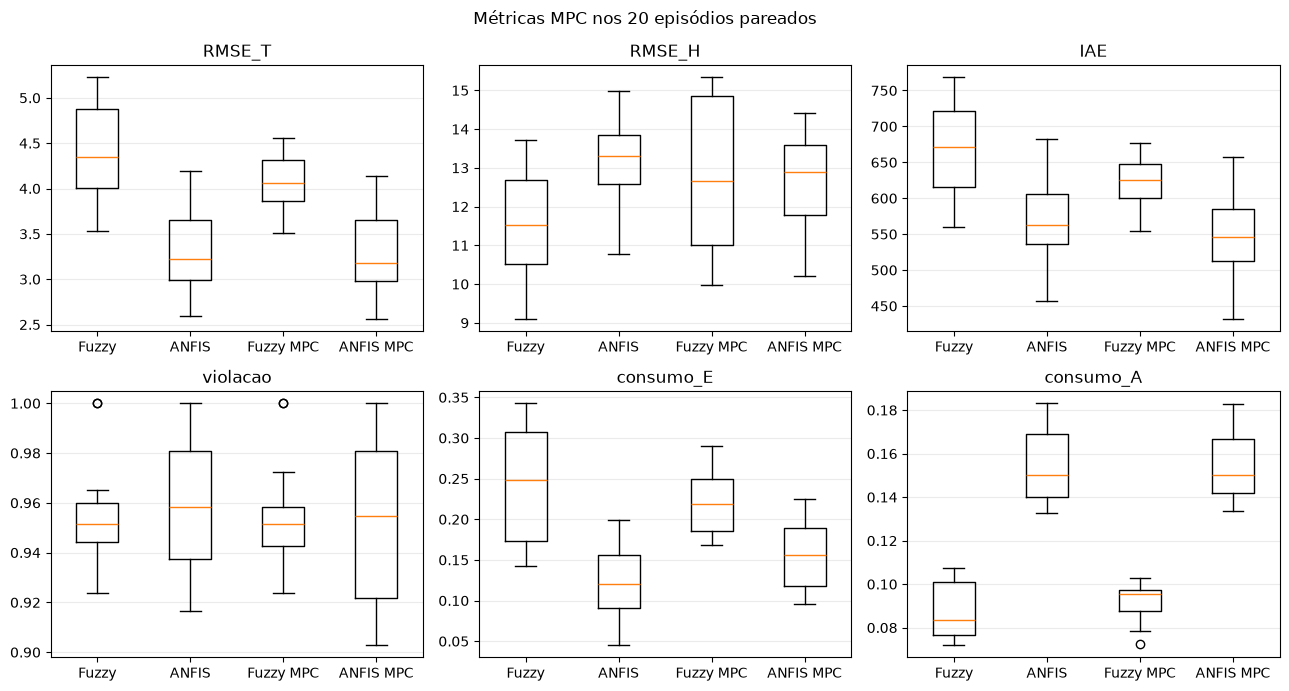

In [15]:
# Trajetórias e distribuição de métricas no episódio final de demonstração e nos 20 pares.
fig, axes = plt.subplots(2,1,figsize=(10,7),sharex=True)
cores = {'fuzzy':'tab:blue','anfis':'tab:orange','fuzzy_mpc':'tab:green','anfis_mpc':'tab:red'}
for ax,var,ref,ylabel in [(axes[0],'temperatura','referencia_t','Temperatura (°C)'),(axes[1],'umidade','referencia_h','Umidade (%)')]:
    for nome in cores:
        d=traj_mpc[nome][1]; ax.plot(d.passo,d[var],label=nome.upper(),color=cores[nome])
    ax.plot(d.passo,d[ref],'k:',label='Referência'); ax.set_ylabel(ylabel); ax.grid(alpha=.25); ax.legend(ncol=2)
axes[-1].set_xlabel('Passo de 10 min'); fig.suptitle('Preditor MLP + MPC — episódio 1')
fig.tight_layout(); fig.savefig(FIG/'mpc_episodio01.png',dpi=160); plt.show()

fig,axes=plt.subplots(2,3,figsize=(13,7))
labels=list(cores)
for ax,m in zip(axes.flat,METRICAS):
    ax.boxplot([tabela_mpc[f'{m}_{name}'] for name in labels]); ax.set_xticks(range(1,5),['Fuzzy','ANFIS','Fuzzy MPC','ANFIS MPC'])
    ax.set_title(m); ax.grid(axis='y',alpha=.25)
fig.suptitle('Métricas MPC nos 20 episódios pareados'); fig.tight_layout()
fig.savefig(FIG/'mpc_metricas_20_episodios.png',dpi=160); plt.show()